# Axe 7 : le graphe des entreprises liées

Certaines annonces du BODACC citent **plusieurs entreprises** à la fois : une procédure étendue à une société liée, un groupe de sociétés jugées ensemble, un dirigeant et sa société… On relie deux entreprises quand elles sont **citées dans la même annonce**. On obtient un graphe d'entreprises liées, et on se demande : retrouve-t-on des **groupes de sociétés** ? Et quand une entreprise du groupe fait faillite, les autres suivent-elles (**contagion**) ?

Les noms des entreprises n'ont pas été gardés au nettoyage : on les décrit par leur **secteur**, leur **forme juridique** et leur **département** (SIRENE).

### Lexique

| Terme | En clair |
|---|---|
| **Annonce collective** | Une annonce BODACC qui cite plusieurs SIREN. |
| **Composante connexe** | Un groupe d'entreprises reliées entre elles, directement ou par l'intermédiaire d'autres. |
| **Holding** | Une société qui détient des parts dans d'autres sociétés (secteur NAF 64 ou 70 : sièges sociaux). |
| **Contagion** | Quand la défaillance d'une entreprise entraîne celle des entreprises qui lui sont liées. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Lien | Deux entreprises sont reliées si elles sont citées dans **la même annonce**. Le poids du lien = le nombre d'annonces en commun. | Luka |
| Très grandes annonces | On écarte les annonces qui citent **plus de 60 entreprises** (une seule, avec 351 SIREN) : c'est une liste groupée, pas un groupe de sociétés, et elle créerait à elle seule 61 000 liens. | Luka |

## 1. Les annonces collectives

In [1]:
import sys
sys.path.append("../../scripts")

import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import louvain_communities, modularity
from data_utils import PROCESSED, NAF_DIVISIONS, mem
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
pd.set_option("display.max_rows", 60)

b = pd.read_parquet(PROCESSED / "bodacc_clean.parquet",
                    columns=["id", "siren", "annonce_collective", "categorie", "nature", "date_evenement"])
coll = b[b["annonce_collective"] & b["siren"].notna()]
taille = coll.groupby("id")["siren"].nunique()
print(f"annonces collectives : {taille.size:,} | lignes : {len(coll):,}".replace(",", " "))
display(taille.value_counts().sort_index().head(10).rename("annonces").to_frame().T)
coll.groupby("id")["categorie"].first().value_counts().to_frame("annonces collectives")

annonces collectives : 8 354 | lignes : 20 822


siren,1,2,3,4,5,6,7,8,9,10
annonces,185,6682,795,290,119,68,69,26,30,21


,annonces collectives
categorie,
autre,3581
issue,2464
entrée en défaillance,1658
aggravation,590
signal précoce,61


### Observations

- On compte **8 354 annonces collectives**. La grande majorité cite **2 entreprises** (6 682 annonces).
- Ce ne sont pas surtout des ouvertures : 3 581 sont des annonces « autres » (dépôts de créances…), 2 464 des issues (clôtures, plans), et seulement 1 658 des entrées en défaillance.

## 2. Le graphe

In [2]:
MAX_PAR_ANNONCE = 60
print("annonces écartées (plus de 60 entreprises) :", (taille > MAX_PAR_ANNONCE).sum(), "| la plus grande :", taille.max())
G = nx.Graph()
for _, sirens in coll[coll["id"].isin(taille.index[taille <= MAX_PAR_ANNONCE])].groupby("id")["siren"]:
    for a, c in itertools.combinations(sorted(set(sirens)), 2):
        G.add_edge(a, c, weight=G[a][c]["weight"] + 1 if G.has_edge(a, c) else 1)
composantes = sorted(nx.connected_components(G), key=len, reverse=True)
tailles = pd.Series([len(c) for c in composantes])
print(G, "| composantes :", len(composantes), "| densité :", f"{nx.density(G):.5f}")
pd.DataFrame({"composantes": tailles.value_counts().sort_index()}).T

annonces écartées (plus de 60 entreprises) : 1 | la plus grande : 351
Graph with 8178 nodes and 15067 edges | composantes : 3159 | densité : 0.00045


,2,3,4,5,6,7,8,9,10,11,...,20,21,23,24,28,32,36,38,47,53
composantes,2512,347,132,44,28,27,12,12,6,6,...,1,2,1,1,1,1,1,1,1,1


### Observations

- Le graphe relie **8 178 entreprises** par **15 067 liens**. Il est très peu dense (0,00045) et découpé en **3 159 morceaux**, dont 2 512 simples **paires**. Le plus gros morceau a 53 entreprises.

In [3]:
# Une composante vient-elle d'une seule annonce (tout le monde relié à tout le monde) ou de plusieurs ?
annonces_de = coll[coll["id"].isin(taille.index[taille <= MAX_PAR_ANNONCE])].groupby("siren")["id"].apply(set)
infos = pd.DataFrame([{"entreprises": len(c), "annonces": len(set().union(*(annonces_de[n] for n in c))),
                       "tout relié (clique)": nx.density(G.subgraph(c)) == 1} for c in composantes])
print("composantes venant d'une seule annonce :", (infos["annonces"] == 1).sum(), "sur", len(infos))
print("composantes formées de plusieurs annonces :", (infos["annonces"] > 1).sum(),
      "| elles regroupent", infos.loc[infos["annonces"] > 1, "entreprises"].sum(), "entreprises")
infos.head(8)

composantes venant d'une seule annonce : 1301 sur 3159
composantes formées de plusieurs annonces : 1858 | elles regroupent 4713 entreprises


,entreprises,annonces,tout relié (clique)
0,53,2,True
1,47,1,True
2,38,26,True
3,36,4,False
4,32,1,True
5,28,1,True
6,24,1,True
7,23,1,True


### Observations

- **3 128 morceaux sur 3 159 sont des cliques** : tout le monde y est relié à tout le monde. Ce sont des groupes cités ensemble, une ou plusieurs fois.
- Seulement **31 morceaux** (212 entreprises) relient des entreprises **par l'intermédiaire d'autres**, à travers des annonces différentes. Le réseau est donc une **juxtaposition de petits groupes fermés**, pas un grand réseau connecté.

In [4]:
# La plus grande composante qui n'est pas une clique (des entreprises reliées par l'intermédiaire d'autres)
print("composantes qui ne sont pas des cliques :", (~infos["tout relié (clique)"]).sum(),
      "| elles regroupent", infos.loc[~infos["tout relié (clique)"], "entreprises"].sum(), "entreprises")
i_multi = infos.index[~infos["tout relié (clique)"]][0]
plus_grande = G.subgraph(composantes[i_multi]).copy()
print(plus_grande)
print("clustering moyen :", round(nx.average_clustering(plus_grande), 3),
      "| plus court chemin moyen :", round(nx.average_shortest_path_length(plus_grande), 2),
      "| diamètre :", nx.diameter(plus_grande))
print("clustering moyen sur tout le graphe :", round(nx.average_clustering(G), 3))

composantes qui ne sont pas des cliques : 31 | elles regroupent 212 entreprises
Graph with 36 nodes and 444 edges
clustering moyen : 0.953 | plus court chemin moyen : 1.32 | diamètre : 3
clustering moyen sur tout le graphe : 0.378


### Observations

- La plus grande composante qui n'est pas une clique compte **36 entreprises** et 444 liens. Elle reste presque une clique (clustering 0,95, 1,3 étape en moyenne entre deux entreprises).

## 3. Qui sont ces entreprises ?

On ajoute les infos SIRENE (secteur, forme juridique, département, âge) et on compare avec **toutes les entreprises entrées en défaillance**.

In [5]:
s = pd.read_parquet(PROCESSED / "sirene_clean.parquet",
                    columns=["siren", "naf_division", "naf_section", "cj_famille", "categorie_juridique", "departement", "date_creation"])
s = s[s["siren"].isin(set(G) | set(b.loc[b["categorie"] == "entrée en défaillance", "siren"].dropna()))]
s = s.set_index("siren")
liees = s.loc[s.index.intersection(list(G))]
defaillantes = s.loc[s.index.intersection(b.loc[b["categorie"] == "entrée en défaillance", "siren"].dropna().unique())]
print(len(liees), "entreprises liées trouvées dans SIRENE |", len(defaillantes), "entreprises défaillantes")

def parts(col, n=8):
    return pd.DataFrame({"liées": liees[col].astype("string").value_counts(normalize=True),
                         "toutes les défaillantes": defaillantes[col].astype("string").value_counts(normalize=True)}
                        ).mul(100).sort_values("liées", ascending=False).head(n).round(1)
parts("naf_division").rename(index=NAF_DIVISIONS)

7757 entreprises liées trouvées dans SIRENE | 913360 entreprises défaillantes


,liées,toutes les défaillantes
naf_division,,
Activités immobilières,26.5,3.5
Commerce de détail,7.6,13.8
Restauration,7.2,12.4
Travaux de construction spécialisés,6.6,20.1
Services financiers,6.2,1.3
Commerce de gros,4.8,5.4
Construction de bâtiments,4.6,3.2
"Culture, production animale, chasse",3.9,1.1


In [6]:
parts("categorie_juridique")

,liées,toutes les défaillantes
categorie_juridique,,
5499,41.1,59.2
6540,15.6,1.0
5710,13.3,22.8
1000,11.2,13.9
5599,7.9,0.6
6599,2.6,0.2
5202,1.9,0.3
6541,1.8,0.2


### Observations

- Les entreprises liées sont très différentes des défaillantes en général. L'**immobilier** représente **26,5 %** des entreprises liées, contre 3,5 % des défaillantes. Les **services financiers** (6,2 % contre 1,3 %) et l'**agriculture** (3,9 % contre 1,1 %) sont aussi plus fréquents. La construction spécialisée l'est beaucoup moins (6,6 % contre 20,1 %).
- Côté forme juridique, les **SCI** (`6540`) font **15,6 %** des entreprises liées, contre 1 % des défaillantes. Les SA (`5599`) aussi sont plus fréquentes (7,9 % contre 0,6 %).
- Ça ressemble à des **groupes patrimoniaux** : une société d'exploitation avec une ou plusieurs SCI qui détiennent ses murs. C'est une hypothèse, que les données ne permettent pas de vérifier sans les liens de capital.

In [7]:
# Les entreprises reliées entre elles sont-elles dans le même département, le même secteur ?
def meme(col, a, c):
    # Vrai si les deux entreprises ont la même valeur (une valeur inconnue compte comme différente)
    m = s[col].astype("string")
    return (m.reindex(a).reset_index(drop=True) == m.reindex(c).reset_index(drop=True)).fillna(False).to_numpy()

aretes = pd.DataFrame(list(G.edges()), columns=["a", "b"])
for col in ["departement", "naf_division", "categorie_juridique"]:
    aretes[col] = meme(col, aretes["a"], aretes["b"])
# Référence : des paires de défaillantes tirées au hasard
rng = np.random.default_rng(0)
idx = defaillantes.index.to_numpy()
hasard = pd.DataFrame({"a": rng.choice(idx, 20000), "b": rng.choice(idx, 20000)})
for col in ["departement", "naf_division", "categorie_juridique"]:
    hasard[col] = meme(col, hasard["a"], hasard["b"])
pd.DataFrame({"paires liées": aretes[["departement", "naf_division", "categorie_juridique"]].mean(),
              "paires au hasard": hasard[["departement", "naf_division", "categorie_juridique"]].mean()}
            ).mul(100).round(1).rename(index={"departement": "même département", "naf_division": "même secteur",
                                              "categorie_juridique": "même forme juridique"})

,paires liées,paires au hasard
même département,74.4,2.1
même secteur,29.2,8.6
même forme juridique,43.0,42.4


### Observations

- **74,4 %** des paires liées sont dans le **même département**, contre **2,1 %** pour des paires de défaillantes tirées au hasard. Les entreprises liées sont presque toujours **au même endroit**.
- **29,2 %** sont dans le **même secteur** (contre 8,6 % au hasard).
- La forme juridique, elle, n'est pas plus souvent la même (43,0 % contre 42,4 %) : des entreprises liées ont souvent des formes différentes (une SARL et une SCI, par exemple).

## 4. Les entreprises centrales

In [8]:
# Les entreprises « carrefours » : celles qui apparaissent dans plusieurs annonces collectives différentes
cent = pd.DataFrame({
    "annonces": annonces_de.map(len),
    "degré": pd.Series(dict(G.degree())),
    "degré pondéré": pd.Series(dict(G.degree(weight="weight"))),
    "intermédiarité": pd.Series(nx.betweenness_centrality(G, normalized=False)),  # nombre de plus courts chemins
}).fillna(0)
cent = cent.join(s[["naf_division", "categorie_juridique", "departement"]].astype("string"))
cent["secteur"] = cent["naf_division"].map(NAF_DIVISIONS)
print("entreprises citées dans au moins 2 annonces collectives différentes :", (cent["annonces"] >= 2).sum())
cent.sort_values(["intermédiarité", "annonces"], ascending=False).head(12)[
    ["annonces", "degré", "intermédiarité", "secteur", "categorie_juridique", "departement"]].round(0)

entreprises citées dans au moins 2 annonces collectives différentes : 4527


,annonces,degré,intermédiarité,secteur,categorie_juridique,departement
349323444,2,30.0,32.0,Activités immobilières,6599,06
510676570,2,30.0,32.0,Activités immobilières,6540,06
441276888,2,16.0,30.0,Construction de bâtiments,6541,44
482281177,3,17.0,17.0,Restauration,5499,37
440092542,2,17.0,17.0,Commerce de détail,1000,37
380947317,2,2.0,16.0,Génie civil,5599,44
344633672,2,30.0,15.0,NaN,6540,06
381631092,2,30.0,15.0,NaN,6541,06
393648704,2,30.0,15.0,Activités immobilières,1000,66
397657339,2,30.0,15.0,NaN,6599,06


### Observations

- **4 527 entreprises** apparaissent dans au moins 2 annonces collectives différentes.
- Les entreprises les plus « ponts » (intermédiarité) ne relient que quelques dizaines de chemins : comme le réseau est fait de cliques, il y a très peu de vrais intermédiaires.

In [9]:
# Les holdings (sièges sociaux, services financiers) sont-elles plus centrales ?
cent["holding"] = cent["naf_division"].isin(["64", "70"])
cent.groupby("holding")[["annonces", "degré"]].mean().round(2).assign(
    entreprises=cent.groupby("holding").size(),
    **{"part dans ≥ 2 annonces": cent.groupby("holding")["annonces"].apply(lambda a: (a >= 2).mean()).round(3)})

,annonces,degré,entreprises,part dans ≥ 2 annonces
holding,,,,
False,2.46,3.60,7690,0.542
True,2.80,4.38,566,0.640


### Observations

- Les **holdings** (sièges sociaux, services financiers : 566 entreprises) sont un peu plus reliées (degré moyen 4,4 contre 3,6) et plus souvent dans plusieurs annonces (64 % contre 54 %).

## 5. Les communautés de la plus grande composante qui n'est pas une clique

Les plus grandes composantes sont des **cliques** : tout le monde y est relié à tout le monde (une seule annonce, ou la même liste répétée), Louvain n'a rien à découper. On regarde donc la plus grande composante **qui n'est pas une clique** : des entreprises reliées par l'intermédiaire d'autres, à travers plusieurs annonces.

In [10]:
comms = sorted(louvain_communities(plus_grande, weight="weight", seed=0), key=len, reverse=True)
print(len(comms), "communautés | modularité :", round(modularity(plus_grande, comms, weight="weight"), 3))
communaute = {n: i + 1 for i, c in enumerate(comms) for n in c}
pd.DataFrame([{"communauté": i, "entreprises": len(c),
               "département principal": s.loc[list(c), "departement"].astype("string").mode().iloc[0],
               "part du département principal": (s.loc[list(c), "departement"].astype("string")
                                                 == s.loc[list(c), "departement"].astype("string").mode().iloc[0]).mean(),
               "secteur principal": NAF_DIVISIONS.get(s.loc[list(c), "naf_division"].astype("string").mode().iloc[0], "?")}
              for i, c in enumerate(comms, 1)]).set_index("communauté").round(2)

4 communautés | modularité : 0.109


,entreprises,département principal,part du département principal,secteur principal
communauté,,,,
1,16,06,0.94,Santé humaine
2,10,06,0.90,Activités immobilières
3,6,06,0.83,Activités immobilières
4,4,06,1.00,Activités immobilières


### Observations

- Dans cette composante de 36 entreprises, Louvain trouve **4 communautés**, mais la modularité est très faible (**0,11**) : la composante est presque une clique.
- Presque toutes ces entreprises sont dans les **Alpes-Maritimes** (06) : de 83 % à 100 % selon la communauté. C'est un groupe local.

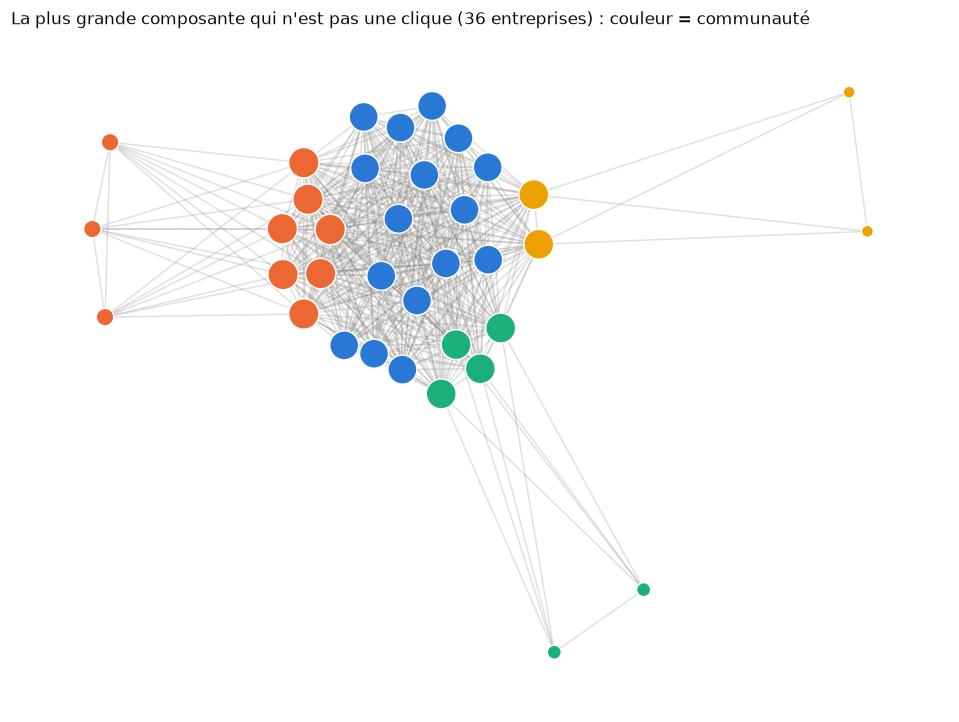

In [11]:
pos = nx.spring_layout(plus_grande, seed=0, k=0.3)
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(plus_grande, pos, ax=ax, alpha=0.25, edge_color=gu.GRIS)
nx.draw_networkx_nodes(plus_grande, pos, ax=ax, node_size=[25 + 12 * plus_grande.degree(n) for n in plus_grande],
                       node_color=[gu.COULEURS[(communaute[n] - 1) % len(gu.COULEURS)] for n in plus_grande],
                       edgecolors="#fcfcfb", linewidths=1)
ax.set_axis_off()
ax.set_title(f"La plus grande composante qui n'est pas une clique ({plus_grande.number_of_nodes()} entreprises) : couleur = communauté",
             loc="left", fontsize=11, color=gu.TITRE)
plt.show()

## 6. Contagion : les entreprises liées font-elles faillite ensemble ?

Pour chaque paire d'entreprises liées, on regarde si **les deux** ont une entrée en défaillance, et l'écart entre leurs **premières** entrées en défaillance. On compare avec des paires d'entreprises défaillantes tirées au hasard.

In [12]:
entree = (b[b["categorie"] == "entrée en défaillance"].dropna(subset=["siren"])
            .groupby("siren")["date_evenement"].min())
aretes["a en défaillance"] = aretes["a"].isin(entree.index)
aretes["b en défaillance"] = aretes["b"].isin(entree.index)
aretes["les deux"] = aretes["a en défaillance"] & aretes["b en défaillance"]
print(f"paires liées où les deux entreprises entrent en défaillance : {aretes['les deux'].mean():.1%}")
deux = aretes[aretes["les deux"]]
ecart = (entree.reindex(deux["a"]).to_numpy() - entree.reindex(deux["b"]).to_numpy()).astype("timedelta64[D]").astype(float)
ecart = np.abs(ecart)
ecart_hasard = np.abs((entree.reindex(hasard["a"]).to_numpy() - entree.reindex(hasard["b"]).to_numpy())
                      .astype("timedelta64[D]").astype(float))
pd.DataFrame({
    "paires liées": [len(ecart), np.mean(ecart == 0), np.mean(ecart <= 30), np.mean(ecart <= 365), np.median(ecart) / 30.44],
    "paires au hasard": [len(ecart_hasard), np.mean(ecart_hasard == 0), np.mean(ecart_hasard <= 30),
                         np.mean(ecart_hasard <= 365), np.median(ecart_hasard) / 30.44],
}, index=["paires", "même jour", "à 30 jours près", "à 1 an près", "écart médian (mois)"]).round(3)

paires liées où les deux entreprises entrent en défaillance : 44.2%


,paires liées,paires au hasard
paires,6666.000,20000.000
même jour,0.416,0.000
à 30 jours près,0.448,0.010
à 1 an près,0.764,0.105
écart médian (mois),2.530,68.922


### Observations

- Dans **44 %** des paires liées, **les deux** entreprises ont une entrée en défaillance.
- Quand c'est le cas, elles entrent en défaillance **le même jour** dans **42 %** des cas, et **à moins d'un an d'écart** dans **76 %** des cas, avec un écart médian de **2,5 mois**. Pour des paires au hasard, c'est 10 % à moins d'un an, avec un écart médian de 69 mois.
- ⚠️ Prudence : une partie de cet effet est **automatique**. Deux entreprises citées dans la même annonce sont souvent jugées ensemble, le même jour (extension de procédure). Les écarts de plusieurs mois, eux, ressemblent davantage à de la **contagion** : une entreprise du groupe tombe, puis les autres suivent.

## 7. Export pour le dashboard

In [13]:
noeuds_df = cent.reset_index().rename(columns={"index": "siren"})
noeuds_df["composante"] = noeuds_df["siren"].map({n: i + 1 for i, c in enumerate(composantes) for n in c})
noeuds_df["communaute_plus_grande"] = noeuds_df["siren"].map(communaute)
noeuds_df[["siren", "degré", "degré pondéré", "intermédiarité", "secteur", "categorie_juridique", "departement",
           "holding", "composante", "communaute_plus_grande"]].rename(
    columns={"degré": "degre", "degré pondéré": "degre_pondere", "intermédiarité": "intermediarite"}
).to_parquet(DASH / "entreprises_liees_noeuds.parquet", index=False)
pd.DataFrame([(u, v, d["weight"]) for u, v, d in G.edges(data=True)], columns=["source", "cible", "annonces"]
            ).to_parquet(DASH / "entreprises_liees_aretes.parquet", index=False)
print("export : entreprises_liees_noeuds, entreprises_liees_aretes")

export : entreprises_liees_noeuds, entreprises_liees_aretes
